# Atelier 1 — De la décision au premier chiffre
HETIC MD5 · 19 novembre 2026 · Bilel Maïz

Steve Landry NONO, Maeva QUENUM, Chantal CAMARA, Stéphane DOMI et Ludovic TUEKAM.

Pour la saison 2027 en Haute-Garonne, quel seuil de danger la direction du SDIS 31 devrait-elle examiner pour couvrir les jours avec feu recensé tout en maîtrisant les jours de surveillance théorique ? J+1 est l’analyse principale. Les seuils ≥2, ≥3 et ≥4 sont des scénarios pédagogiques.

Voir le PDF compagnon pour A–F et le rapport Markdown pour l’installation, les sources et les limites. Le calcul est relançable depuis la racine ou depuis le dossier du notebook. Les ZIP BDIFF ont été collectés avec une validation TLS non confirmée. L’archive météo `date` est interprétée comme la date de référence avant décalage. L’équivalence avec `Reference_time` reste à corroborer.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import date
from hashlib import sha256
from zipfile import ZipFile
import io
import json
import os
import sys
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'scripts/calculer_scenarios_q2_q3.py').is_file())
sys.path.insert(0, str(root))
from scripts import calculer_scenarios_q2_q3 as moteur

years = (2024, 2025)
dep = '31'
occ = sorted(moteur.OCC)
sources = root / 'datasets/public'
meteo_meta = json.loads((sources / 'meteo_des_forets/manifest.json').read_text())['extractions']
bdiff_meta = json.loads((sources / 'bdiff_officiel/manifest.json').read_text())['extractions']

## Contrôles de fichiers et grains
Les codes sont des chaînes. Les dates BDIFF sont celles de première alerte. Les contrôles portent sur les champs utiles. Les valeurs absentes feraient échouer le calcul. L’année météo 2026 est contrôlée puis exclue de la jointure faute d’export BDIFF comparable.

In [2]:
quality = []
weather = []
fires = []
for entry in meteo_meta:
    path = root / entry['fichier']
    assert path.stat().st_size == entry['taille_octets']
    moteur.verify_sha(path, entry['sha256'])
    raw = pd.read_csv(path, sep=entry['separateur_csv'], dtype='string')
    keys = ['date', 'num_dep', 'niveau_j1', 'niveau_j2']
    raw['num_dep'] = raw.num_dep.str.strip().str.zfill(2)
    missing = int(raw[keys].isna().sum().sum())
    duplicates = int(raw.duplicated(['num_dep', 'date']).sum())
    assert missing == duplicates == 0
    assert len(raw) + 1 == entry['lignes_y_compris_entete']
    assert raw.num_dep.str.fullmatch(r'(?:[0-9]{2}|2A|2B)').all()
    assert set(occ) <= set(raw.num_dep)
    assert raw[keys[2:]].isin(['1', '2', '3', '4']).all().all()
    raw['reference'] = pd.to_datetime(raw['date'].str[:10], format='%Y-%m-%d')
    year = int(entry['annee_archive'])
    assert raw.reference.dt.year.eq(year).all()
    quality.append(['MdF', year, len(raw), len(raw[raw.num_dep.isin(occ)]),
                    missing, duplicates, raw.reference.min().date(), raw.reference.max().date()])
    if year in years:
        weather.append(raw.loc[raw.num_dep.isin(occ), ['num_dep', 'reference', *keys[2:]]])
for entry in bdiff_meta:
    path = sources / 'bdiff_officiel' / entry['fichier']
    assert path.stat().st_size == entry['octets']
    moteur.verify_sha(path, entry['sha256'])
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        assert set(archive.namelist()) == set(entry['controle']['fichiers'])
        text = archive.read('Incendies.csv').decode('utf-8-sig')
    criteria = text.splitlines()[1]
    assert 'OCCITANIE' in criteria and 'Type de feu : F' in criteria
    assert all(f'{entry["annee"]}-{bound}' in criteria for bound in ('01-01', '12-31'))
    raw = pd.read_csv(io.StringIO(text), skiprows=2, sep=';', dtype='string')
    raw = raw.rename(columns={'Département':'dep', 'Date de première alerte':'alerte',
                              'Code INSEE':'commune', 'Numéro':'id'})
    raw['dep'] = raw.dep.str.zfill(2)
    raw['jour'] = pd.to_datetime(raw.alerte.str[:10], format='%Y-%m-%d')
    missing = int(raw[['dep','alerte','commune','id','Année']].isna().sum().sum())
    duplicates = int(raw.duplicated(['Année','id']).sum())
    year = entry['annee']
    assert missing == duplicates == 0
    assert len(raw) == entry['controle']['lignes']
    assert raw.jour.dt.year.eq(year).all() and raw['Année'].eq(str(year)).all()
    assert raw.dep.isin(occ).all() and raw.commune.str.fullmatch(r'[0-9]{5}').all()
    assert raw.commune.str[:2].eq(raw.dep).all()
    quality.append(['BDIFF', year, len(raw), len(raw), missing, duplicates,
                    raw.jour.min().date(), raw.jour.max().date()])
    fires.append(raw[['dep','jour','commune']])
quality = pd.DataFrame(quality, columns=['source','année','lignes','Occitanie','manquants',
                                        'doublons','début observé','fin observée'])
display(quality)

,source,année,lignes,Occitanie,manquants,doublons,début observé,fin observée
0,MdF,2024,11520,1560,0,0,2024-06-03,2024-09-30
1,MdF,2025,11520,1560,0,0,2025-06-03,2025-09-30
2,MdF,2026,12576,1703,0,0,2026-05-28,2026-10-05
3,BDIFF,2024,413,413,0,0,2024-01-01,2024-12-29
4,BDIFF,2025,472,472,0,0,2025-01-10,2025-12-31


## Jointures et exclusions
Chaque échéance est portée au jour de validité par ajout de 1 ou 2 jours calendaires. L’intersection J+1/J+2 et la jointure avec BDIFF sont 1:1 au grain département × jour. Plusieurs événements peuvent appartenir au même jour. Un zéro après jointure signifie « aucun feu de type F recensé dans l’export ». Les jours sans prévision commune restent hors cohorte.

In [3]:
weather = pd.concat(weather, ignore_index=True).rename(columns={'num_dep':'dep'})
fires = pd.concat(fires, ignore_index=True)
key = ['dep','jour']
def echeance(offset):
    level = f'niveau_j{offset}'
    frame = weather[['dep','reference',level]].copy()
    frame['jour'] = frame.reference + pd.to_timedelta(offset, unit='D')
    assert (frame.jour > frame.reference).all()
    assert frame.jour.dt.year.isin(years).all()
    return frame.rename(columns={level:f'j{offset}'})[key+[f'j{offset}']].astype({f'j{offset}':'int'})

availability = echeance(1).merge(echeance(2), on=key, how='outer',
                                  validate='one_to_one', indicator='horizons')
days = fires.groupby(key).size().rename('evenements').reset_index()
joined = availability.merge(days, on=key, how='outer',
                            validate='one_to_one', indicator='origine')
common = joined.loc[joined.horizons.eq('both')].copy()
common['evenements'] = common.evenements.fillna(0).astype(int)
common['feu'] = common.evenements.gt(0)

def select(frame, year, territory):
    selected = frame[frame.jour.dt.year.eq(year)]
    return selected if territory == 'Occitanie' else selected[selected.dep.eq(territory)]

audit = []
for year in years:
    for territory in (dep, 'Occitanie'):
        full = select(joined, year, territory)
        cohort = select(common, year, territory)
        event_rows = select(fires, year, territory)
        event_days = full.evenements.notna()
        audit.append([year, territory, int(full.horizons.eq('left_only').sum()),
                      int(full.horizons.eq('right_only').sum()), len(cohort), len(event_rows),
                      int(event_days.sum()), int((event_days & full.horizons.eq('left_only')).sum()),
                      int((event_days & full.horizons.eq('right_only')).sum()),
                      int(full.origine.eq('right_only').sum()), int(cohort.feu.sum()),
                      len(event_rows) - int(cohort.evenements.sum())])
audit = pd.DataFrame(audit, columns=['année','territoire','J+1 seul (jours)','J+2 seul (jours)',
    'jours communs','événements BDIFF','jours feu BDIFF','jours feu J+1 seul','jours feu J+2 seul',
    'jours feu sans météo','jours feu retenus','événements exclus'])
display(audit)
display(common.assign(année=common.jour.dt.year).groupby('année').jour.agg(['min','max']))

,année,territoire,J+1 seul (jours),J+2 seul (jours),jours communs,événements BDIFF,jours feu BDIFF,jours feu J+1 seul,jours feu J+2 seul,jours feu sans météo,jours feu retenus,événements exclus
0,2024,31,1,1,119,1,1,0,0,1,0,1
1,2024,Occitanie,13,13,1547,413,289,1,0,129,159,163
2,2025,31,1,1,119,4,4,0,0,0,4,0
3,2025,Occitanie,13,13,1547,472,340,0,2,130,208,167


,min,max
année,,
2024,2024-06-05,2024-10-01
2025,2025-06-05,2025-10-01


## Indicateurs et normalisation
Pour chaque année, territoire, échéance et seuil, N désigne les jours éligibles, F les jours avec feu, S les jours activés et C leur intersection. La couverture vaut 100 C/F, la charge relative 100 S/N et la part de jours activés avec feu 100 C/S. Le nombre de jours avec feu manqués est F−C et son taux vaut 100 (F−C)/F. Un dénominateur nul donne une valeur non définie. Les jours de surveillance représentent une charge théorique.

In [4]:
def ratio(numerator, denominator):
    return round(100 * numerator / denominator, 2) if denominator else None

results = []
for year in years:
    for territory in ['Occitanie', *occ]:
        subset = select(common, year, territory)
        for horizon, column in [('J+1','j1'), ('J+2','j2')]:
            for threshold in (2, 3, 4):
                active = subset[column].ge(threshold)
                n, f = len(subset), int(subset.feu.sum())
                s, c = int(active.sum()), int((active & subset.feu).sum())
                results.append(dict(annee=year, territoire=territory, horizon=horizon, seuil=threshold,
                    jours_eligibles=n, jours_avec_feu_observe=f, jours_surveillance=s,
                    jours_feu_couverts=c, jours_feu_non_couverts=f-c,
                    jours_surveillance_sans_feu_observe=s-c, couverture_feu_pct=ratio(c,f),
                    mobilisation_pct=ratio(s,n), feux_observes_type_f=int(subset.evenements.sum()),
                    jours_activés_avec_feu_pct=ratio(c,s), jours_feu_manqués_pct=ratio(f-c,f)))
kpi = pd.DataFrame(results)
kpi31 = kpi[kpi.territoire.eq(dep)]
display(kpi31)

,annee,territoire,horizon,seuil,jours_eligibles,jours_avec_feu_observe,jours_surveillance,jours_feu_couverts,jours_feu_non_couverts,jours_surveillance_sans_feu_observe,couverture_feu_pct,mobilisation_pct,feux_observes_type_f,jours_activés_avec_feu_pct,jours_feu_manqués_pct
30,2024,31,J+1,2,119,0,16,0,0,16,NaN,13.45,0,0.00,NaN
31,2024,31,J+1,3,119,0,1,0,0,1,NaN,0.84,0,0.00,NaN
32,2024,31,J+1,4,119,0,0,0,0,0,NaN,0.00,0,NaN,NaN
33,2024,31,J+2,2,119,0,12,0,0,12,NaN,10.08,0,0.00,NaN
34,2024,31,J+2,3,119,0,1,0,0,1,NaN,0.84,0,0.00,NaN
35,2024,31,J+2,4,119,0,0,0,0,0,NaN,0.00,0,NaN,NaN
114,2025,31,J+1,2,119,4,51,2,2,49,50.0,42.86,4,3.92,50.0
115,2025,31,J+1,3,119,4,10,2,2,8,50.0,8.40,4,20.00,50.0
116,2025,31,J+1,4,119,4,0,0,4,0,0.0,0.00,4,NaN,100.0
117,2025,31,J+2,2,119,4,47,2,2,45,50.0,39.50,4,4.26,50.0


## Sensibilité et concentration
Les seuils sont comparés sur les mêmes jours. J+2 vérifie la dépendance à l’horizon. Le scénario illustratif ≥3 sert aussi à comparer moyenne et médiane des années où F est positif. La couverture agrégée divise les totaux C et F, et le retrait de l’année dominante teste la dépendance à une seule saison. Les moyennes de charge incluent les deux années.

In [5]:
summary = []
for horizon in ('J+1','J+2'):
    for threshold in (2,3,4):
        rows = kpi31[kpi31.horizon.eq(horizon) & kpi31.seuil.eq(threshold)]
        dominant = rows.loc[rows.jours_avec_feu_observe.idxmax()]
        rest = rows[rows.annee.ne(dominant.annee)]
        n, f, s, c = (int(rows[col].sum()) for col in
                      ['jours_eligibles','jours_avec_feu_observe','jours_surveillance','jours_feu_couverts'])
        summary.append([horizon,threshold,n,f,s,c,ratio(c,f),ratio(s,n),
                        rows.couverture_feu_pct.count(), rows.couverture_feu_pct.mean(),
                        rows.couverture_feu_pct.median(), rows.jours_surveillance.mean(),
                        rows.jours_surveillance.median(), int(dominant.annee),
                        ratio(int(dominant.jours_avec_feu_observe),f),
                        ratio(int(rest.jours_feu_couverts.sum()),int(rest.jours_avec_feu_observe.sum()))])
summary = pd.DataFrame(summary, columns=['horizon','seuil','N','F','S','C','couverture %',
    'charge %','années avec couverture définie','moyenne couverture %','médiane couverture %',
    'moyenne jours activés','médiane jours activés','année dominante','part dominante %',
    'couverture hors année dominante %'])
display(summary)

,horizon,seuil,N,F,S,C,couverture %,charge %,années avec couverture définie,moyenne couverture %,médiane couverture %,moyenne jours activés,médiane jours activés,année dominante,part dominante %,couverture hors année dominante %
0,J+1,2,238,4,67,2,50.0,28.15,1,50.0,50.0,33.5,33.5,2025,100.0,None
1,J+1,3,238,4,11,2,50.0,4.62,1,50.0,50.0,5.5,5.5,2025,100.0,None
2,J+1,4,238,4,0,0,0.0,0.00,1,0.0,0.0,0.0,0.0,2025,100.0,None
3,J+2,2,238,4,59,2,50.0,24.79,1,50.0,50.0,29.5,29.5,2025,100.0,None
4,J+2,3,238,4,11,2,50.0,4.62,1,50.0,50.0,5.5,5.5,2025,100.0,None
5,J+2,4,238,4,0,0,0.0,0.00,1,0.0,0.0,0.0,0.0,2025,100.0,None


## Diagnostic complémentaire BDIFF × superficie
Le référentiel public Ecolab « Surface - commune » (INSEE/IGN) donne des hectares de territoire. Le cliché du 01/01/2025 est appliqué aux deux années par convention de géographie fixe. La superficie de toutes les communes du 31 est comptée une seule fois, indépendamment de la présence d’événements. Ce ratio annuel utilise tous les événements type F des exports BDIFF. Il documente une fréquence rapportée au territoire total, avec un biais lié à la part boisée. Les exports comparables de 2021 à 2023 restent indisponibles pour ce calcul. Le catalogue des archives météo ne fournit que 2024–2026 et le service a commencé en 2023.

Le fichier est téléchargé en HTTPS si `ATELIER_SURFACE_CSV` n’est pas défini. La copie locale ou téléchargée doit avoir le SHA-256 vérifié ci-dessous.

In [6]:
surface_url = 'https://static.data.gouv.fr/resources/surface/20261126-125656/surface-commune.csv'
surface_sha = 'e1a5eb3f42d5be506add598a8c838b10872b36013bb05306d0a47c8546a6c347'
cache = os.environ.get('ATELIER_SURFACE_CSV')
if cache:
    surface_bytes = Path(cache).read_bytes()
else:
    with urlopen(surface_url, timeout=45) as response:
        surface_bytes = response.read()
assert sha256(surface_bytes).hexdigest() == surface_sha
surface = pd.read_csv(io.BytesIO(surface_bytes), dtype={'geocode_commune':'string'})
geo = surface.loc[surface.date_mesure.eq('2025-01-01') &
                  surface.geocode_commune.str.fullmatch(r'31[0-9]{3}', na=False),
                  ['geocode_commune','valeur']].rename(columns={'geocode_commune':'commune','valeur':'ha'})
assert not geo.commune.duplicated().any() and geo.ha.gt(0).all()
total_ha = float(geo.ha.sum())
local_fires = fires[fires.dep.eq(dep)]
territorial = local_fires.merge(geo, on='commune', how='left',
                                validate='many_to_one', indicator=True)
area_audit = territorial.assign(année=territorial.jour.dt.year).groupby('année')['_merge'].value_counts().unstack()
display(area_audit)
assert territorial._merge.eq('both').all() and len(territorial) == len(local_fires)
history = territorial.groupby(territorial.jour.dt.year).size().rename('feux').rename_axis('année').reset_index()
assert tuple(history['année']) == years
history['ha'] = total_ha
history['feux / 1 000 ha'] = 1000 * history.feux / history.ha
print(f'Superficie de référence : {len(geo)} communes, {total_ha:,.0f} ha')
display(history)
history_stats = dict(moyenne=float(history['feux / 1 000 ha'].mean()),
                     médiane=float(history['feux / 1 000 ha'].median()),
                     part_max=ratio(int(history.feux.max()),int(history.feux.sum())))
print(history_stats)

_merge,left_only,right_only,both
année,,,
2024,0,0,1
2025,0,0,4


Superficie de référence : 586 communes, 630,990 ha


,année,feux,ha,feux / 1 000 ha
0,2024,1,630990.0,0.001585
1,2025,4,630990.0,0.006339


{'moyenne': 0.003962027924372811, 'médiane': 0.003962027924372811, 'part_max': 80.0}


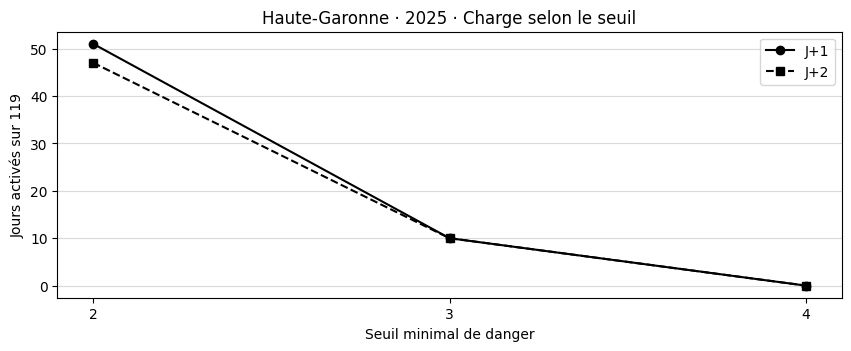

In [7]:
fig, ax = plt.subplots(figsize=(8.4,3.4), layout='constrained')
plot = kpi31[kpi31.annee.eq(2025)]
for horizon, marker, style in [('J+1','o','-'), ('J+2','s','--')]:
    subset = plot[plot.horizon.eq(horizon)]
    ax.plot(subset.seuil, subset.jours_surveillance, color='black',
            marker=marker, linestyle=style, label=horizon)
ax.set(xticks=[2,3,4], xlabel='Seuil minimal de danger', ylabel='Jours activés sur 119',
       title='Haute-Garonne · 2025 · Charge selon le seuil')
ax.grid(axis='y', color='.85')
ax.legend()
plt.show()

### Lecture en trois phrases
Un passage de 51 à 10 jours activés pourrait suggérer une couverture fortement dégradée. Sur la cohorte haute-garonnaise de 2025, les seuils ≥2 et ≥3 couvrent chacun 2 jours avec feu sur 4 en J+1 comme en J+2. Le seuil ≥4 perd ces deux jours dans les deux horizons, tandis que le retrait de 2025 rend la couverture indéfinie et empêche de conclure à une préférence stable pour 2027.

In [8]:
reference = pd.read_csv(root / 'docs/resultats/kpi_scenarios_q2_q3.csv',
                        dtype={'territoire':'string'}).drop(columns='unite_cout')
pd.testing.assert_frame_equal(kpi[reference.columns], reference, check_dtype=False)
assert len(common) == 3094 and len(kpi) == 168
assert (kpi.jours_feu_non_couverts + kpi.jours_feu_couverts == kpi.jours_avec_feu_observe).all()
assert (kpi.jours_surveillance_sans_feu_observe + kpi.jours_feu_couverts == kpi.jours_surveillance).all()
assert kpi.loc[kpi.jours_avec_feu_observe.eq(0),'couverture_feu_pct'].isna().all()
assert kpi.groupby(['annee','territoire']).jours_eligibles.nunique().eq(1).all()
print('PASS — 168 KPI identiques, cohortes communes et identités de comptage vérifiées.')
if os.environ.get('ATELIER_PREUVES'):
    output = Path(os.environ['ATELIER_PREUVES'])
    output.mkdir(parents=True, exist_ok=True)
    for name, frame in [('kpi31',kpi31), ('audit',audit), ('summary',summary),
                        ('history',history), ('quality',quality)]:
        frame.to_csv(output / f'{name}.csv', index=False)
    fig.savefig(output / 'charge.pdf')
    fig.savefig(output / 'charge.png', dpi=180)

PASS — 168 KPI identiques, cohortes communes et identités de comptage vérifiées.
